In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import scipy.stats as stats
import warnings

In [4]:
nsduh_2021_2024 = pd.read_csv('nsduh_2021_2024.csv')
nsduh_2021_2024.head()

C:\Users\jkirk\AppData\Local\Temp\ipykernel_11608\3405685789.py:1: DtypeWarning: Columns (2281: GQTYPE2) have mixed types. Specify dtype option on import or set low_memory=False.
  nsduh_2021_2024 = pd.read_csv('nsduh_2021_2024.csv')


,YEAR,AGE3,PDEN10,NEWRACE2,IRINSUR4,IRHHSIZ2,IRPINC3,IRFAMIN3,IRKI17_2,IRHH65_2,...,ANYNEDFLAG,ANYNEDYR,FPIMFNMYR,ILIMFOTHFG,ILIMFOTHYR,ILIMFOTHMN,ANALWT2_C1,ANALWT2_C2,ANALWT2_C3,ANALWT2_C4
0,2021,8,2,1,1,2,2,2,2,1,...,-9.0,-9.0,-9,-9,-9,-9,732.884779,366.442389,244.294926,183.221195
1,2021,11,1,1,1,2,7,7,1,3,...,-9.0,-9.0,-9,-9,-9,-9,11710.016142,5855.008071,3903.338714,2927.504035
2,2021,6,2,1,1,2,1,4,1,1,...,-9.0,-9.0,-9,-9,-9,-9,466.934414,233.467207,155.644805,116.733603
3,2021,9,1,1,1,3,1,3,2,1,...,-9.0,-9.0,-9,-9,-9,-9,11070.439576,5535.219788,3690.146525,2767.609894
4,2021,6,1,7,2,1,1,1,1,1,...,-9.0,-9.0,-9,-9,-9,-9,218.379769,109.189885,72.793256,54.594942


In [5]:
conditions = [
    (nsduh_2021_2024["TOBMON"] == 1),
     (nsduh_2021_2024["TOBYR"] == 1) & (nsduh_2021_2024["TOBMON"] == 0),
      (nsduh_2021_2024["TOBFLAG"] == 1) & (nsduh_2021_2024["TOBMON"] == 0)
       & (nsduh_2021_2024["TOBYR"] == 0)
]

In [ ]:
choices = ['1', '2', '3']

nsduh_2021_2024["tob_use"] = np.select(conditions, choices, default='9')

C:\Users\jkirk\AppData\Local\Temp\ipykernel_11608\1255239715.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  nsduh_2021_2024["tob_use"] = np.select(conditions, choices, default='9')


In [ ]:
tob_use = nsduh_2021_2024["tob_use"]
alc_use = nsduh_2021_2024["IRALCRC"]
marij_use = nsduh_2021_2024["IRMJRC"]
coc_use = nsduh_2021_2024["IRCOCRC"]
crck_use = nsduh_2021_2024["IRCRKRC"]
heroi_use = nsduh_2021_2024["IRHERRC"]
meth_use = nsduh_2021_2024["IRMETHAMREC"]
hallu_use = nsduh_2021_2024["IRHALLUCREC"]
stim_use = nsduh_2021_2024["STMNMREC"]
painre_use = nsduh_2021_2024["IRPNRNMREC"]
fent_use = nsduh_2021_2024["IRIMFREC"]

tob_use.head(10)

0    1
1    3
2    9
3    1
4    9
5    1
6    1
7    9
8    9
9    9
Name: tob_use, dtype: int64

In [8]:
work_situ_pastwk = nsduh_2021_2024["WRKSTATWK2"]
unemployment_reason = nsduh_2021_2024["WRKRSNJOB"]
num_jobs_pastyr = nsduh_2021_2024["WRKNUMJOB2"]
hours_worked = nsduh_2021_2024["WRKDHRSWK2"] 
hours_worked_clean = hours_worked[hours_worked < 61]
work_situ = nsduh_2021_2024["IRWRKSTAT"]
rec_foodstamp = nsduh_2021_2024["IRFSTAMP"]
family_income = nsduh_2021_2024["IRFAMIN3"]

In [41]:
nsduh_2021_2024["IRPNRNMREC"].value_counts()

IRPNRNMREC
9    213498
3     12016
2      5042
1      1885
Name: count, dtype: int64

Text(0.5, 9.444444444444427, 'Hours Worked (past week)')

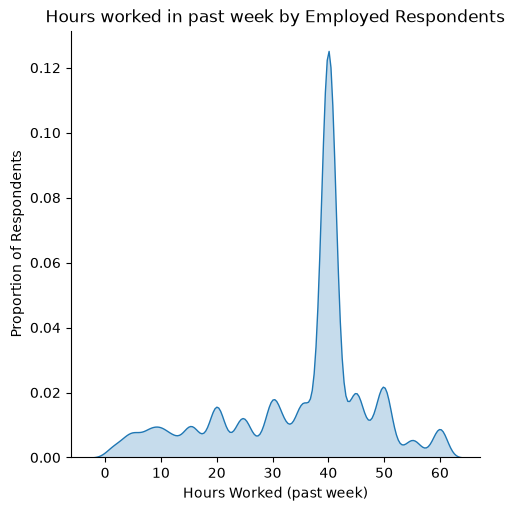

In [53]:
sns.displot(data=nsduh_2021_2024, x=hours_worked_clean, kind="kde", fill=True)

plt.title("Hours worked in past week by Employed Respondents")
plt.ylabel("Proportion of Respondents")
plt.xlabel("Hours Worked (past week)")

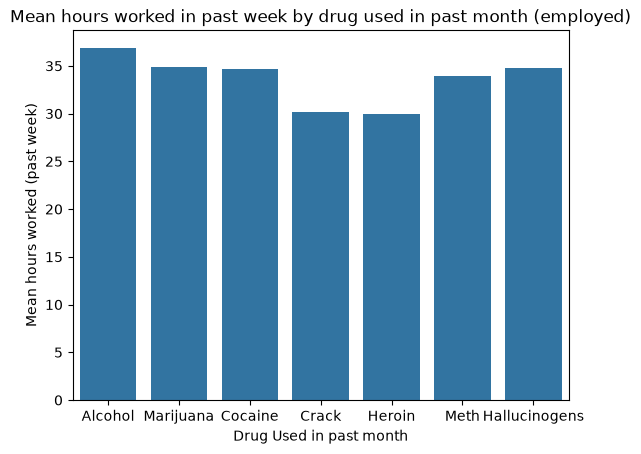

In [51]:
drugs = {"Alcohol": "IRALCRC", "Marijuana": "IRMJRC", "Cocaine": "IRCOCRC", "Crack": "IRCRKRC",
"Heroin": "IRHERRC", "Meth": "IRMETHAMREC", "Hallucinogens": "IRHALLUCREC"}
avg_hours = {name: hours_worked_clean[nsduh_2021_2024[col] == 1].mean() for name, col in drugs.items()}

sns.barplot(x=list(avg_hours.keys()), y=list(avg_hours.values()))
plt.title("Mean hours worked in past week by drug used in past month (employed)")
plt.ylabel("Mean hours worked (past week)")
plt.xlabel("Drug Used in past month")
plt.show()

In [56]:
print(pd.Series(avg_hours).round(2))

Alcohol          36.87
Marijuana        34.91
Cocaine          34.71
Crack            30.13
Heroin           29.91
Meth             33.98
Hallucinogens    34.73
dtype: float64


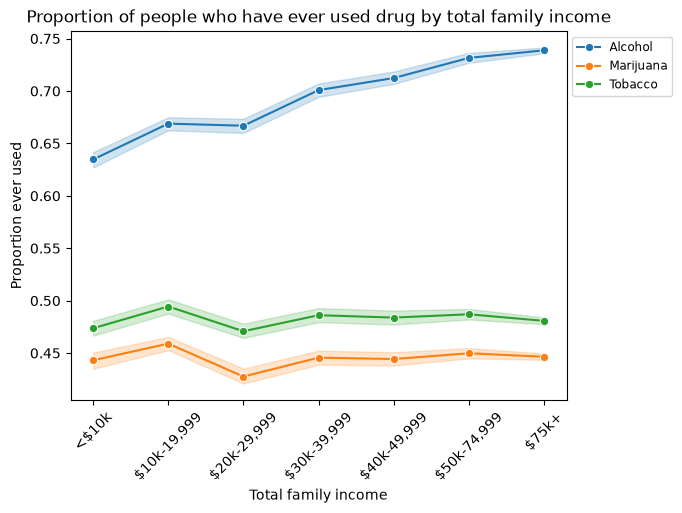

In [37]:
nsduh_2021_2024["tob_use"] = nsduh_2021_2024["tob_use"].astype(int)

for name, col in {"Alcohol": "IRALCRC", "Marijuana": "IRMJRC", "Tobacco": "tob_use"}.items():
    sns.lineplot(x=nsduh_2021_2024["IRFAMIN3"], y=nsduh_2021_2024[col].isin(EVER), label=name, marker="o")

plt.xticks(range(1, 8), ["<$10k", "$10k-19,999", "$20k-29,999", "$30k-39,999",
"$40k-49,999", "$50k-74,999", "$75k+"], rotation=45)
plt.title("Proportion of people who have ever used drug by total family income")
plt.xlabel("Total family income")
plt.ylabel("Proportion ever used")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize="small")
plt.show()

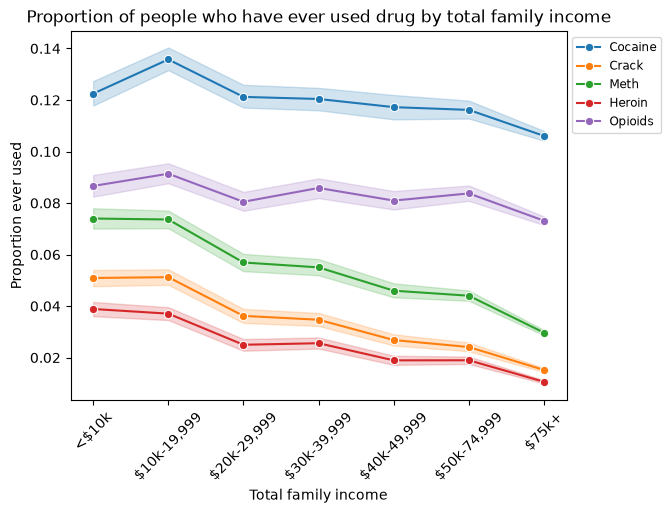

In [38]:
for name, col in {"Cocaine": "IRCOCRC", "Crack": "IRCRKRC", "Meth": "IRMETHAMREC", "Heroin": "IRHERRC", "Opioids": "PNRNMREC"}.items():
    sns.lineplot(x=nsduh_2021_2024["IRFAMIN3"], y=nsduh_2021_2024[col].isin(EVER), label=name, marker="o")

plt.xticks(range(1, 8), ["<$10k", "$10k-19,999", "$20k-29,999", "$30k-39,999",
"$40k-49,999", "$50k-74,999", "$75k+"], rotation=45)
plt.title("Proportion of people who have ever used drug by total family income")
plt.xlabel("Total family income")
plt.ylabel("Proportion ever used")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize="small")
plt.show()

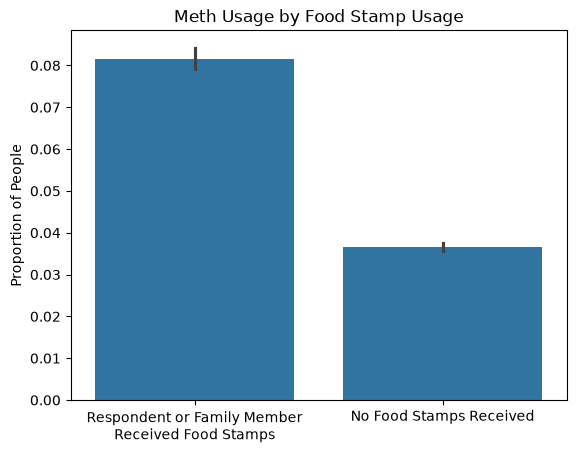

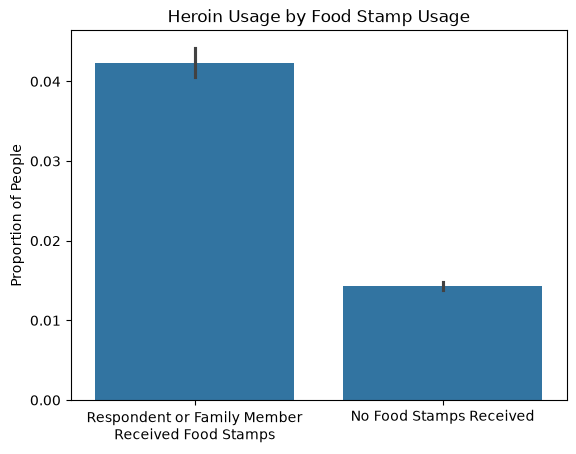

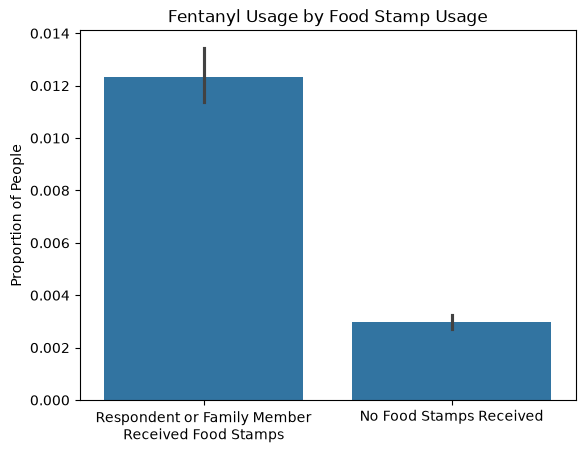

In [54]:
sns.barplot(x=nsduh_2021_2024["IRFSTAMP"], y=nsduh_2021_2024["IRMETHAMREC"].isin([1, 2, 3]))   # x: 1 = yes, 2 = no
plt.title("Meth Usage by Food Stamp Usage")
plt.xticks([0, 1], ["Respondent or Family Member\nReceived Food Stamps",
"No Food Stamps Received"])
plt.xlabel("")
plt.ylabel("Proportion of People")
plt.show()

sns.barplot(x=nsduh_2021_2024["IRFSTAMP"], y=nsduh_2021_2024["IRHERRC"].isin([1, 2, 3]))
plt.title("Heroin Usage by Food Stamp Usage")
plt.xticks([0, 1], ["Respondent or Family Member\nReceived Food Stamps",
"No Food Stamps Received"])
plt.xlabel("")
plt.ylabel("Proportion of People")
plt.show()

sns.barplot(x=nsduh_2021_2024["IRFSTAMP"], y=nsduh_2021_2024["IRIMFREC"].isin([1, 2, 3]))
plt.title("Fentanyl Usage by Food Stamp Usage")
plt.xticks([0, 1], ["Respondent or Family Member\nReceived Food Stamps",
"No Food Stamps Received"])
plt.xlabel("")
plt.ylabel("Proportion of People")
plt.show()

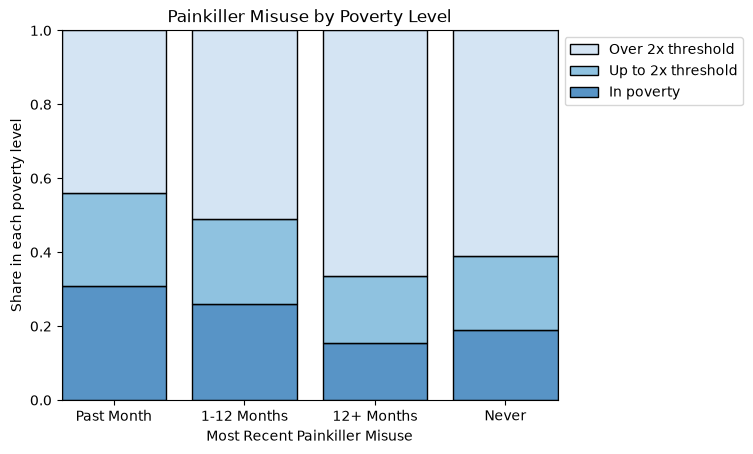

In [55]:
legend =sns.histplot(x=nsduh_2021_2024["IRPNRNMREC"].replace(9, 4),
             hue=nsduh_2021_2024["POVERTY3"].map({1: "In poverty", 2: "Up to 2x threshold", 3: "Over 2x threshold"}),
             hue_order=["Over 2x threshold", "Up to 2x threshold", "In poverty"],
             multiple="fill", discrete=True, shrink=0.8, palette="Blues")

sns.move_legend(legend, "upper left", bbox_to_anchor=(1, 1), title=None)
plt.title("Painkiller Misuse by Poverty Level")
plt.xticks([1, 2, 3, 4], ["Past Month", "1-12 Months", "12+ Months", "Never"])
plt.xlabel("Most Recent Painkiller Misuse")
plt.ylabel("Share in each poverty level")
plt.show()